# Model ML

In [ ]:
import pandas as pd

In [2]:
pr = pd.read_csv('data/problems40000.csv')

In [3]:
pr = pr[pr['avg_rating'] != 0]

In [4]:
pr.drop(['read_books','recomendations','recom_ratings','Unnamed: 0'],axis=1,inplace=True)

In [5]:
df = pd.read_csv('D:\Escritorio\casebooks_SBC\interactions.csv') 
#aqui es directori adient ja que no hi cap a github

In [6]:
df.drop(['is_read','is_reviewed'],axis=1,inplace=True)

In [7]:
df_merged = pr.merge(df[['user_id', 'book_id', 'rating']], on='user_id', how='inner')

In [20]:
df_merged

,user_id,Fantasy,Fiction,Mystery,Poetry,History,Romance,Non-fiction,Children,Young-adult,Comics,avg_pages,counts,avg_rating,book_id,rating
0,357865,8,6,7,9,3,10,4,5,1,2,304,66,1.644737,8001,1
1,357865,8,6,7,9,3,10,4,5,1,2,304,66,1.644737,8000,3
2,357865,8,6,7,9,3,10,4,5,1,2,304,66,1.644737,1473,4
3,357865,8,6,7,9,3,10,4,5,1,2,304,66,1.644737,7968,3
4,357865,8,6,7,9,3,10,4,5,1,2,304,66,1.644737,586,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2561245,627641,5,8,6,10,3,9,4,7,2,1,221,31,2.527778,1088,5
2561246,627641,5,8,6,10,3,9,4,7,2,1,221,31,2.527778,7785,4
2561247,627641,5,8,6,10,3,9,4,7,2,1,221,31,2.527778,16948,4
2561248,627641,5,8,6,10,3,9,4,7,2,1,221,31,2.527778,19459,3


### books with pages

In [21]:
bk = pd.read_csv('casebooks/data/genresxbook.csv')

FileNotFoundError: [Errno 2] No such file or directory: 'casebooks/data/genresxbook.csv'

In [ ]:
bk

Afegim el numero de pagines a aquest dataset per tenir més dades dels llibres

In [ ]:
import pandas as pd
import json

# Lista para almacenar los datos de cada línea
data_list = []

# Abre y lee el archivo línea por línea
with open('D:\Escritorio\casebooks_SBC\sm_filtered_books.json', 'r',encoding='utf-8') as file:
    for line in file:
        # Decodifica cada línea como un objeto JSON y añádela a la lista
        data_list.append(json.loads(line))

# Crea un DataFrame a partir de la lista
json_df = pd.DataFrame(data_list)

# Procesa y combina los datos como en el ejemplo anterior
json_df['book_id'] = json_df['book_id'].astype(str)
json_df['num_pages'] = pd.to_numeric(json_df['num_pages'], errors='coerce')
pages_df = json_df[['book_id', 'num_pages']]

# Suponiendo que tu dataframe bk está cargado y tiene una columna 'book_id'
bk['book_id'] = bk['book_id'].astype(str)
bk_merge = bk.merge(pages_df, on='book_id', how='left')

In [ ]:
bk_merge.to_csv('casebooks/data/genres_pages_x_books.csv')

### final dataset

In [9]:
bk_merge = pd.read_csv('data/genres_pages_x_books.csv')

In [10]:
bk_merge.drop('Unnamed: 0',axis=1,inplace=True)

In [11]:
final_dataset = df_merged.merge(bk_merge, on='book_id', how='inner')

In [22]:
final_dataset

,user_id,Fantasy_x,Fiction_x,Mystery_x,Poetry_x,History_x,Romance_x,Non-fiction_x,Children_x,Young-adult_x,...,Fiction_y,Mystery_y,Poetry_y,History_y,Romance_y,Non-fiction_y,Children_y,Young-adult_y,Comics_y,num_pages
0,357865,8,6,7,9,3,10,4,5,1,...,0.157,0.551,0.162,0.130,0.000,0.0,0.000,0.000,0.0,400.0
1,67954,8,7,6,10,3,9,4,5,2,...,0.157,0.551,0.162,0.130,0.000,0.0,0.000,0.000,0.0,400.0
2,86482,8,1,5,10,2,9,3,7,4,...,0.157,0.551,0.162,0.130,0.000,0.0,0.000,0.000,0.0,400.0
3,283915,8,7,5,10,2,9,6,4,3,...,0.157,0.551,0.162,0.130,0.000,0.0,0.000,0.000,0.0,400.0
4,167403,8,5,7,10,2,9,3,6,1,...,0.157,0.551,0.162,0.130,0.000,0.0,0.000,0.000,0.0,400.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2561245,137417,8,4,7,9,1,10,5,6,3,...,0.581,0.157,0.157,0.026,0.000,0.0,0.009,0.000,0.0,96.0
2561246,137417,8,4,7,9,1,10,5,6,3,...,0.062,0.000,0.000,0.000,0.500,0.0,0.000,0.062,0.0,NaN
2561247,137417,8,4,7,9,1,10,5,6,3,...,0.000,0.000,0.000,0.000,0.167,0.0,0.000,0.000,0.0,245.0
2561248,137417,8,4,7,9,1,10,5,6,3,...,0.000,0.000,0.556,0.000,0.000,0.0,0.444,0.000,0.0,452.0


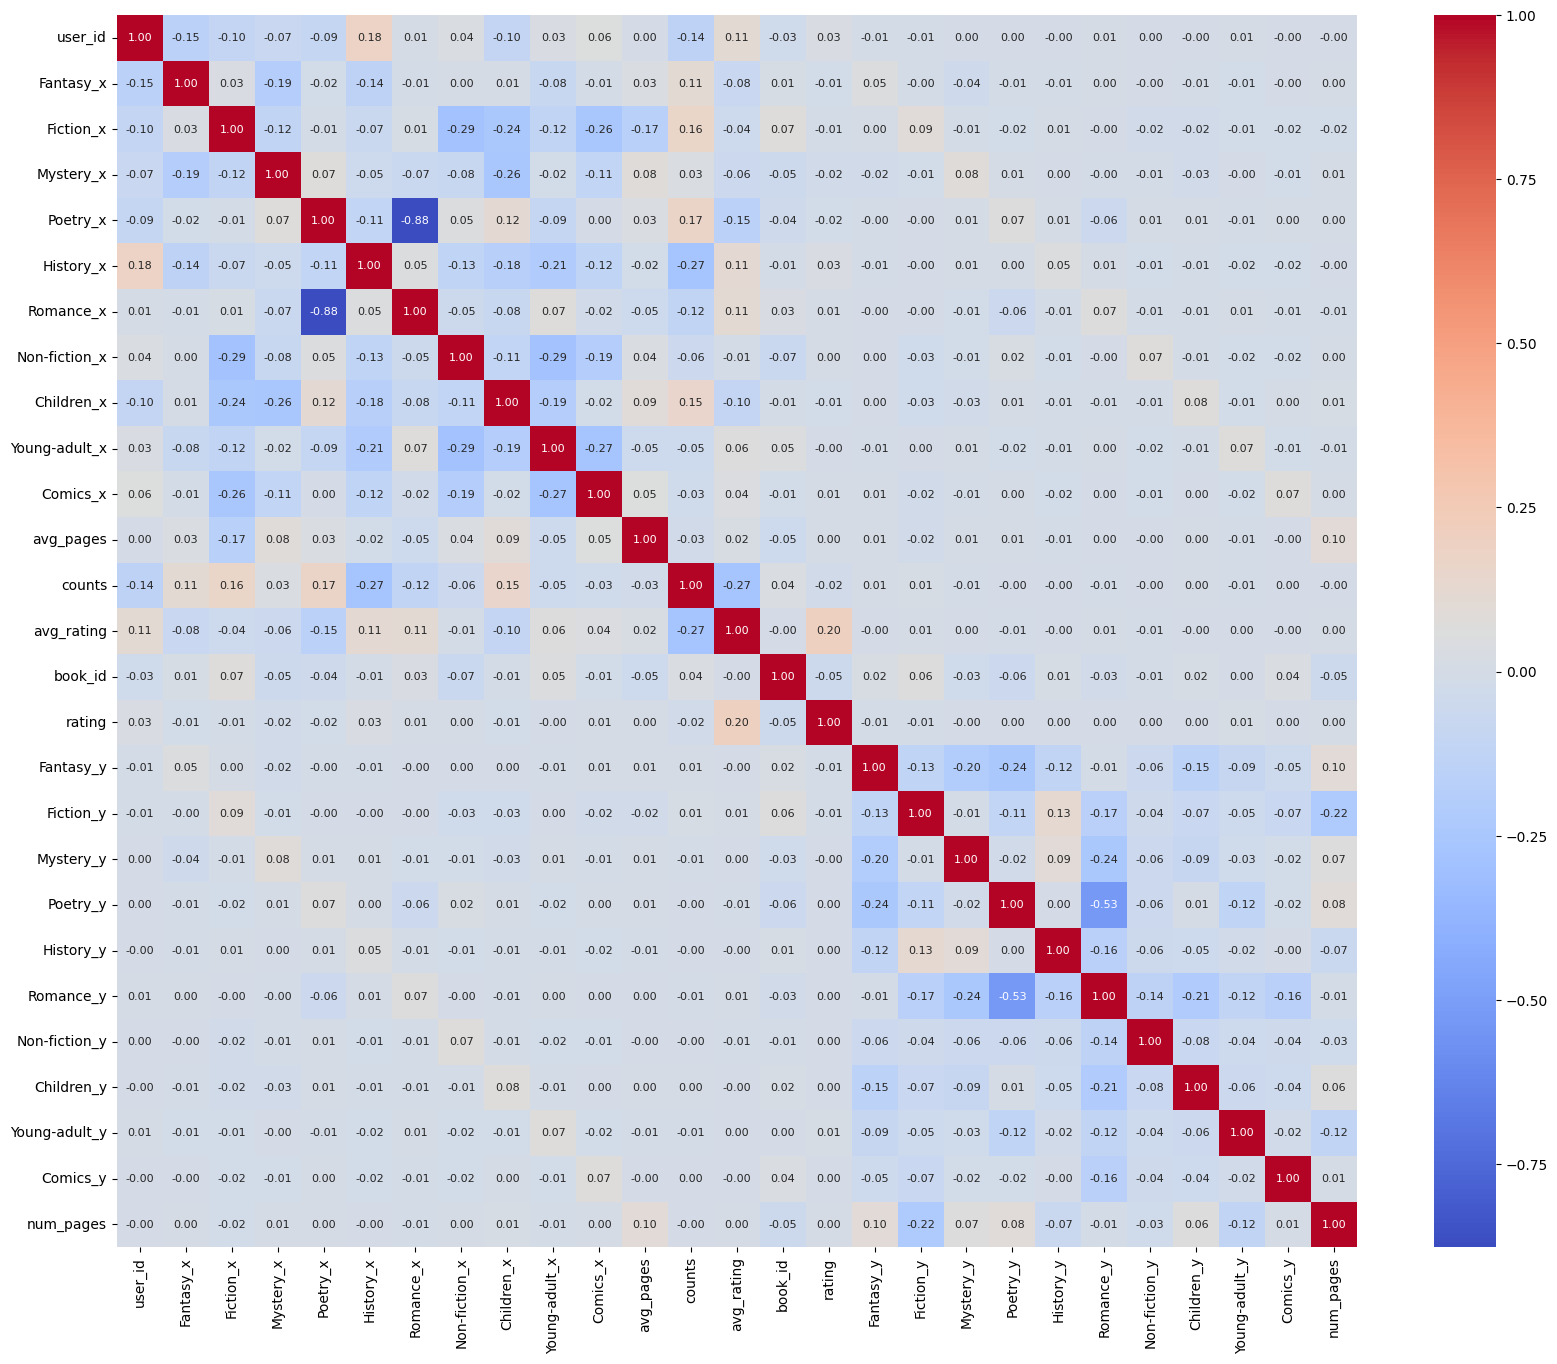

In [23]:
import seaborn as sns
import matplotlib.pyplot as plt

# Ajustar el tamaño de la figura a algo más grande
plt.figure(figsize=(20, 16))  # Tamaño más grande para mejor visualización

# Calcular la matriz de correlación
correlation_matrix = final_dataset.corr()

# Crear el mapa de calor
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='coolwarm', annot_kws={"size":8})

# Ajustar el tamaño de la fuente de las anotaciones si es necesario
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
    
# Mostrar el gráfico
plt.show()


In [ ]:
#final_dataset.drop(columns=["num_pages","Comics_y", "Romance_y", "History_y","Poetry_y","Mystery_y","Fantasy_y","Non-fiction_y","Poetry_x"], inplace=True)

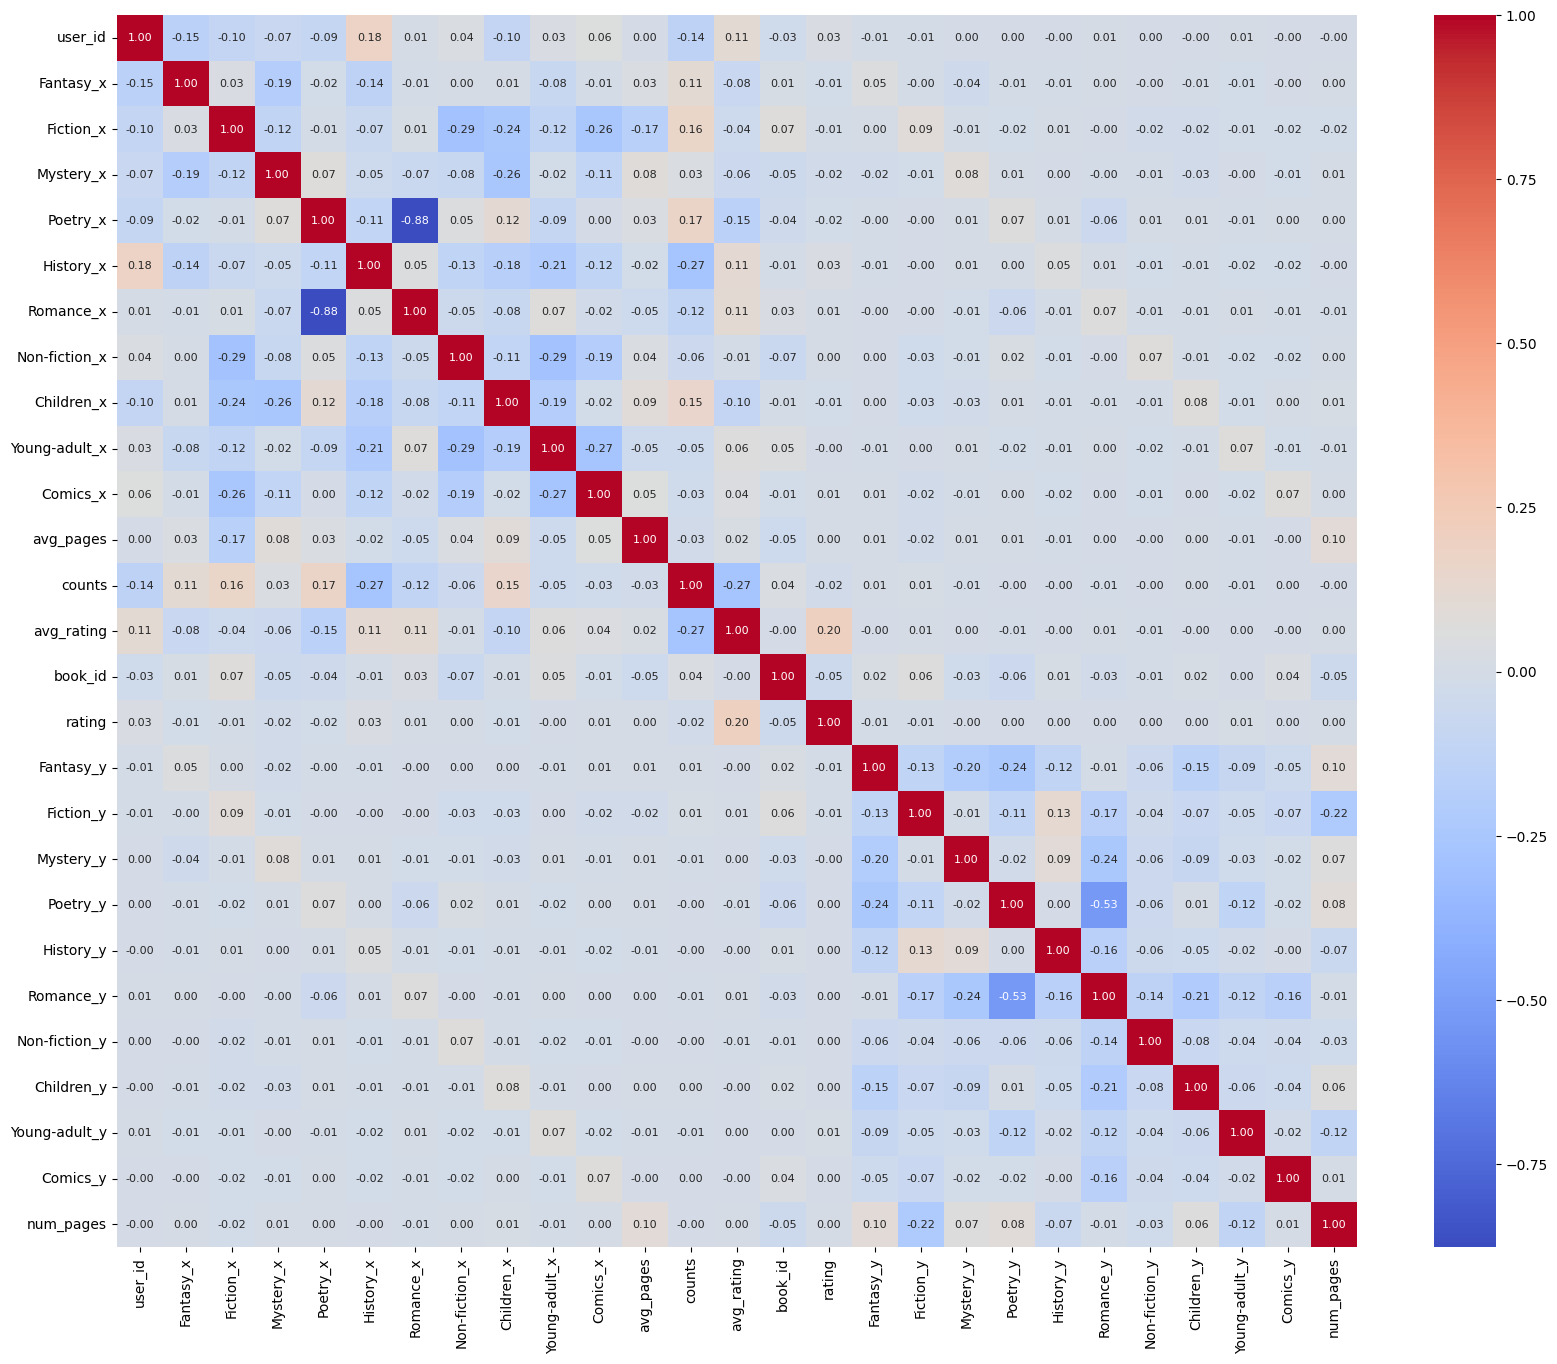

In [38]:
import seaborn as sns
import matplotlib.pyplot as plt

# Ajustar el tamaño de la figura a algo más grande
plt.figure(figsize=(20, 16))  # Tamaño más grande para mejor visualización

# Calcular la matriz de correlación
correlation_matrix = final_dataset.corr()

# Crear el mapa de calor
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='coolwarm', annot_kws={"size":8})

# Ajustar el tamaño de la fuente de las anotaciones si es necesario
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

# Mostrar el gráfico
plt.show()


In [14]:
final_dataset.columns

Index(['user_id', 'Fantasy_x', 'Fiction_x', 'Mystery_x', 'Poetry_x',
       'History_x', 'Romance_x', 'Non-fiction_x', 'Children_x',
       'Young-adult_x', 'Comics_x', 'avg_pages', 'counts', 'avg_rating',
       'book_id', 'rating', 'Fantasy_y', 'Fiction_y', 'Mystery_y', 'Poetry_y',
       'History_y', 'Romance_y', 'Non-fiction_y', 'Children_y',
       'Young-adult_y', 'Comics_y', 'num_pages'],
      dtype='object')

In [24]:
a = final_dataset.drop(columns=["num_pages","Comics_y", "Children_y","Non-fiction_y", "History_y","Poetry_y","Mystery_y","Fantasy_y","Young-adult_y"])

In [47]:
a.columns

Index(['user_id', 'Fantasy_x', 'Fiction_x', 'Mystery_x', 'Poetry_x',
       'History_x', 'Romance_x', 'Non-fiction_x', 'Children_x',
       'Young-adult_x', 'Comics_x', 'avg_pages', 'counts', 'avg_rating',
       'book_id', 'rating', 'Fiction_y', 'Romance_y'],
      dtype='object')

In [ ]:
a

#### Eliminar NAs

In [16]:
notnas = final_dataset.dropna()

In [17]:
notnas2 = a.dropna()

In [37]:
notnas

,user_id,Fantasy_x,Fiction_x,Mystery_x,Poetry_x,History_x,Romance_x,Non-fiction_x,Children_x,Young-adult_x,...,Fiction_y,Mystery_y,Poetry_y,History_y,Romance_y,Non-fiction_y,Children_y,Young-adult_y,Comics_y,num_pages
0,357865,8,6,7,9,3,10,4,5,1,...,0.157,0.551,0.162,0.130,0.000,0.0,0.000,0.0,0.0,400.0
1,67954,8,7,6,10,3,9,4,5,2,...,0.157,0.551,0.162,0.130,0.000,0.0,0.000,0.0,0.0,400.0
2,86482,8,1,5,10,2,9,3,7,4,...,0.157,0.551,0.162,0.130,0.000,0.0,0.000,0.0,0.0,400.0
3,283915,8,7,5,10,2,9,6,4,3,...,0.157,0.551,0.162,0.130,0.000,0.0,0.000,0.0,0.0,400.0
4,167403,8,5,7,10,2,9,3,6,1,...,0.157,0.551,0.162,0.130,0.000,0.0,0.000,0.0,0.0,400.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2561243,137417,8,4,7,9,1,10,5,6,3,...,0.000,0.000,0.000,0.000,0.128,0.0,0.000,0.0,0.0,304.0
2561245,137417,8,4,7,9,1,10,5,6,3,...,0.581,0.157,0.157,0.026,0.000,0.0,0.009,0.0,0.0,96.0
2561247,137417,8,4,7,9,1,10,5,6,3,...,0.000,0.000,0.000,0.000,0.167,0.0,0.000,0.0,0.0,245.0
2561248,137417,8,4,7,9,1,10,5,6,3,...,0.000,0.000,0.556,0.000,0.000,0.0,0.444,0.0,0.0,452.0


In [ ]:
X = a.drop(['rating','user_id','book_id'], axis=1)

In [27]:
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from tqdm import tqdm
from xgboost.callback import TrainingCallback

# Suponiendo que 'a' es tu DataFrame
X = a.drop(['rating','user_id','book_id'], axis=1)
y = a['rating']

# Dividir los datos
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Clase para mostrar el progreso usando tqdm
class TQDMCallback(TrainingCallback):
    def __init__(self, total):
        self.pbar = tqdm(total=total)
    def after_iteration(self, model, epoch, evals_log):
        self.pbar.update(1)
        return False  # Return True para detener el entrenamiento

# Instanciar el modelo XGBoost con early_stopping_rounds
xgb_model = xgb.XGBRegressor(
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    gamma=0,
    reg_alpha=0.1,
    reg_lambda=1,
    early_stopping_rounds=10
)

# Entrenar el modelo con barra de progreso
xgb_model.fit(
    X_train, 
    y_train, 
    eval_set=[(X_test, y_test)],
    callbacks=[TQDMCallback(1000)],
    verbose=False   
)

# Predecir y evaluar
predictions = xgb_model.predict(X_test)
rmse = mean_squared_error(y_test, predictions, squared=False)


  0%|          | 0/1000 [00:00<?, ?it/s]C:\Users\llumf\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.9_qbz5n2kfra8p0\LocalCache\local-packages\Python39\site-packages\xgboost\sklearn.py:861: UserWarning: `callbacks` in `fit` method is deprecated for better compatibility with scikit-learn, use `callbacks` in constructor or`set_params` instead.
  warnings.warn(
100%|██████████| 1000/1000 [35:26<00:00,  2.13s/it] 


In [32]:
rmse

1.2621784328358439

In [35]:
import pickle

# Guardar el modelo a un archivo
with open('xgb_model.pkl', 'wb') as file:
    pickle.dump(xgb_model, file)


In [36]:
# Guardar el modelo a un archivo
xgb_model.save_model('xgb_model.json')


### Decision tree

In [43]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score,classification_report
import matplotlib.pyplot as plt

In [44]:
X = notnas.drop(['rating','user_id'],axis=True)
X['book_id'] = X['book_id'].astype('category')
y = notnas['rating']

In [45]:
X.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 2070113 entries, 0 to 2561249
Data columns (total 25 columns):
 #   Column         Dtype   
---  ------         -----   
 0   Fantasy_x      int64   
 1   Fiction_x      int64   
 2   Mystery_x      int64   
 3   Poetry_x       int64   
 4   History_x      int64   
 5   Romance_x      int64   
 6   Non-fiction_x  int64   
 7   Children_x     int64   
 8   Young-adult_x  int64   
 9   Comics_x       int64   
 10  avg_pages      int64   
 11  counts         int64   
 12  avg_rating     float64 
 13  book_id        category
 14  Fantasy_y      float64 
 15  Fiction_y      float64 
 16  Mystery_y      float64 
 17  Poetry_y       float64 
 18  History_y      float64 
 19  Romance_y      float64 
 20  Non-fiction_y  float64 
 21  Children_y     float64 
 22  Young-adult_y  float64 
 23  Comics_y       float64 
 24  num_pages      float64 
dtypes: category(1), float64(12), int64(12)
memory usage: 408.0 MB


In [48]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Asumiendo que X e y ya están definidos:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Crear y entrenar el modelo de Random Forest
model = RandomForestClassifier(
    n_estimators=300,  # Número de árboles en el bosque.
    criterion='gini',  # Puedes probar 'entropy' para ver si mejora el rendimiento.
    max_depth=20,  # Profundidad máxima del árbol.
    min_samples_split=2,  # Número mínimo de muestras requeridas para dividir un nodo.
    min_samples_leaf=1,  # Número mínimo de muestras requeridas para ser una hoja.
    max_features='sqrt',  # Establecer explícitamente a 'sqrt' según la advertencia.
    max_leaf_nodes=None,  # Número máximo de nodos hoja.
    bootstrap=True,  # Utilizar muestras de bootstrap para construir árboles.
    random_state=42,
    n_jobs=-1,  # Número de trabajos en paralelo.
    oob_score=True  # Usar muestras fuera de la bolsa para estimar la precisión general.
)

model.fit(X_train, y_train)

# Realizar predicciones en el conjunto de prueba
y_pred = model.predict(X_test)

# Calcular la precisión del modelo
accuracy = accuracy_score(y_test, y_pred)
print(f'Precisión del modelo: {accuracy:.2f}')

# También podemos ver la importancia de las características
feature_importances = model.feature_importances_


In [22]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score

# Asumiendo que X e y ya están definidos:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Definir un diccionario con los parámetros que quieres probar
param_grid = {
    'n_estimators': [100, 200, 300],  # Probar con 100, 200 y 300 árboles
    'criterion': ['gini', 'entropy'],  # Funciones para medir la calidad de una división
    'max_depth': [None, 10, 20],  # Profundidades máximas del árbol
}

# Crear el modelo de Grid Search con un RandomForestClassifier
grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,  # Número de pliegues en la validación cruzada
    n_jobs=-1,  # Usar todos los procesadores disponibles
    verbose=2  # Mostrar más información durante el entrenamiento
)

# Ajustar el modelo Grid Search al conjunto de entrenamiento
grid_search.fit(X_train, y_train)

# Obtener los mejores parámetros
best_params = grid_search.best_params_
print(f'Mejores parámetros: {best_params}')

# Crear y entrenar el modelo con los mejores parámetros
best_model = grid_search.best_estimator_

# Realizar predicciones en el conjunto de prueba con el mejor modelo
y_pred = best_model.predict(X_test)

# Calcular la precisión del mejor modelo
accuracy = accuracy_score(y_test, y_pred)
print(f'Precisión del mejor modelo: {accuracy:.2f}')

## OUTPUT DE UN ALTRE NOTEBOOK:
"""Fitting 5 folds for each of 18 candidates, totalling 90 fits
Mejores parámetros: {'criterion': 'gini', 'max_depth': 20, 'n_estimators': 300}
Precisión del mejor modelo: 0.46"""

Fitting 5 folds for each of 18 candidates, totalling 90 fits


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Crear y entrenar el modelo de árbol de decisiones
model = DecisionTreeClassifier(random_state=42)
model.fit(X_train, y_train)

# Realizar predicciones en el conjunto de prueba
y_pred = model.predict(X_test)

# Calcular la precisión del modelo
accuracy = accuracy_score(y_test, y_pred)
print(f'Precisión del modelo: {accuracy:.2f}')

Precisión del modelo: 0.40


C:\Users\llumf\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.9_qbz5n2kfra8p0\LocalCache\local-packages\Python39\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Recall and F-score are ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\llumf\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.9_qbz5n2kfra8p0\LocalCache\local-packages\Python39\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Recall and F-score are ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\llumf\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.9_qbz5n2kfra8p0\LocalCache\local-packages\Python39\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarni

              precision    recall  f1-score   support

           1       0.00      0.00      0.00         0
           2       0.01      0.22      0.02        23
           3       0.19      0.45      0.26      1054
           4       0.58      0.42      0.49      5638
           5       0.59      0.49      0.53      4548

    accuracy                           0.45     11263
   macro avg       0.27      0.32      0.26     11263
weighted avg       0.54      0.45      0.48     11263



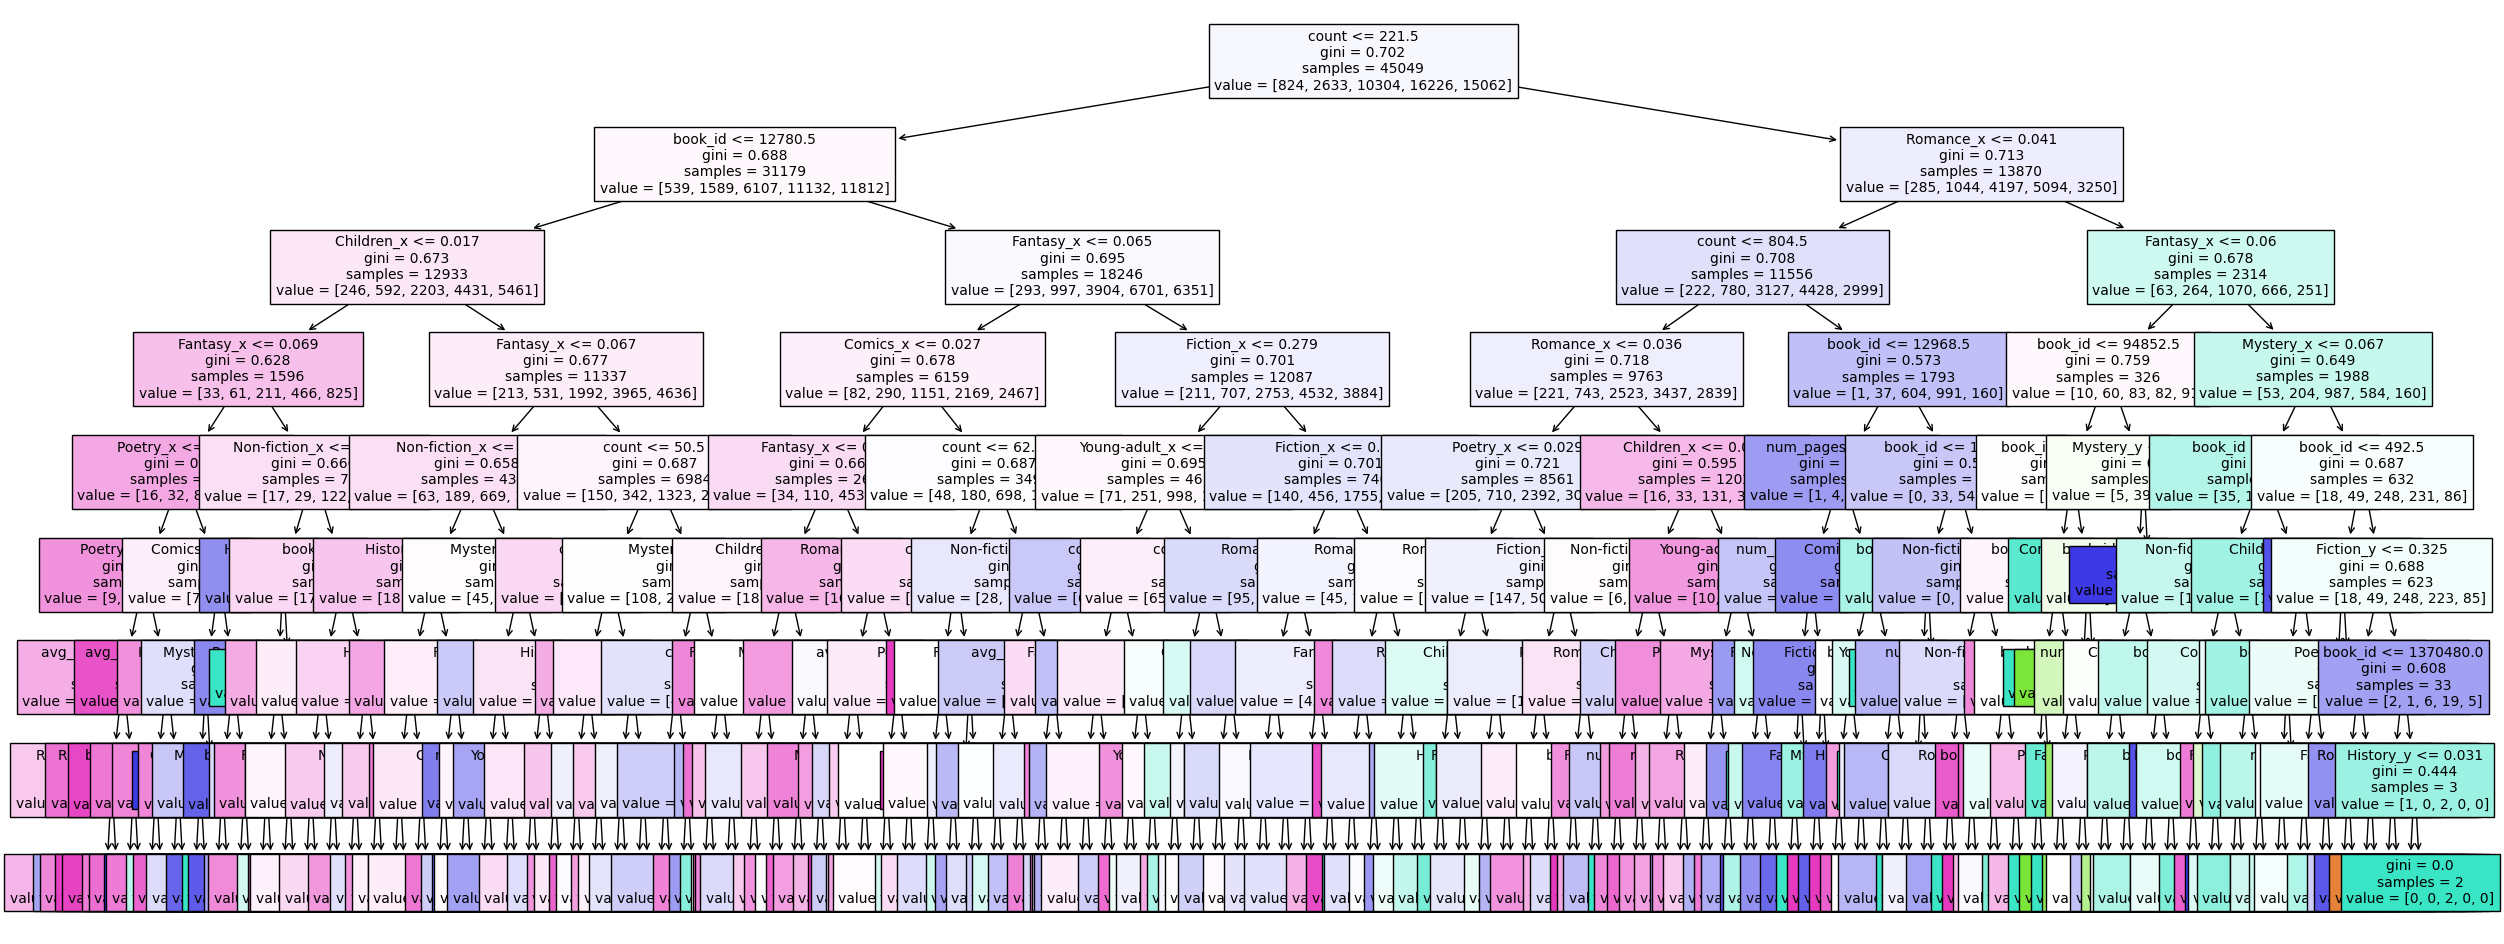

In [ ]:
columnes = X.columns
model = DecisionTreeClassifier(max_depth=8, random_state=10)
model = model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_pred = y_pred
y_testid = y_test.to_numpy()
print(classification_report(y_pred,y_test))

plt.figure(figsize=(30,12))  # set plot size (denoted in inches)
plot_tree(model, fontsize=10, feature_names = columnes, filled=True)
plt.show()

### MLP

In [42]:
X.columns

Index(['Fantasy_x', 'Fiction_x', 'Mystery_x', 'Poetry_x', 'History_x',
       'Romance_x', 'Non-fiction_x', 'Children_x', 'Young-adult_x', 'Comics_x',
       'avg_pages', 'book_id', 'Unnamed: 0', 'Fantasy_y', 'Fiction_y',
       'Mystery_y', 'Poetry_y', 'History_y', 'Romance_y', 'Non-fiction_y',
       'Children_y', 'Young-adult_y', 'Comics_y', 'num_pages', 'Fantasy'],
      dtype='object')

Diferencia entre el llibre i el lector

In [46]:
genres = ['Fantasy', 'Fiction', 'Mystery', 'Poetry', 'History',
          'Romance', 'Non-fiction', 'Children', 'Young-adult', 'Comics']
for gen in genres:
    X[gen] = X[f'{gen}_x']-X[f'{gen}_y']
    X.drop([f'{gen}_x',f'{gen}_y'],axis=1,inplace=True)
X['pagines'] = X['avg_pages']-X['num_pages']

In [19]:
import tensorflow as tf
from keras.models import Sequential
from keras.layers import Dense, GlobalMaxPooling1D, Conv1D, GlobalAveragePooling1D

In [27]:
from sklearn.decomposition import PCA
import numpy as np
pca = PCA(n_components=0.90, svd_solver='full')
X_pca = pca.fit_transform(X)

# Determinar la nova dimensionalitat que sigui una potència de 2 més propera
dim = 2**int(np.ceil(np.log2(pca.n_components_)))
pca = PCA(n_components=dim)
X_pca = pca.fit_transform(X)

In [50]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [51]:
from keras.utils import to_categorical

num_classes = 6

y_train_one_hot = to_categorical(y_train, num_classes=num_classes)
y_test_one_hot = to_categorical(y_test, num_classes=num_classes)

model = Sequential()
model.add(Dense(128,activation='relu'))
model.add(Dense(128,activation='relu'))
model.add(Dense(num_classes,activation = 'softmax'))

# Compile the model
model.compile(optimizer='adamax', loss='categorical_crossentropy', metrics=['accuracy'])

# Train the model
batch_size = 256
epochs = 10

model.fit(X_train, y_train_one_hot, batch_size=batch_size, epochs=epochs)

# Evaluate the model on the test set

loss, accuracy = model.evaluate(X_test, y_test_one_hot, batch_size=batch_size)
print(f"Test accuracy: {accuracy:.2f}")

Epoch 1/10
188/188 [==============================] - 1s 2ms/step - loss: 642.4183 - accuracy: 0.2637
Epoch 2/10
188/188 [==============================] - 0s 2ms/step - loss: 453.1314 - accuracy: 0.2724
Epoch 3/10
188/188 [==============================] - 0s 2ms/step - loss: 508.3568 - accuracy: 0.2638
Epoch 4/10
188/188 [==============================] - 0s 2ms/step - loss: 378.7693 - accuracy: 0.2683
Epoch 5/10
188/188 [==============================] - 0s 2ms/step - loss: 353.8218 - accuracy: 0.2747
Epoch 6/10
188/188 [==============================] - 0s 2ms/step - loss: 390.1304 - accuracy: 0.2682
Epoch 7/10
188/188 [==============================] - 0s 2ms/step - loss: 391.4257 - accuracy: 0.2704
Epoch 8/10
188/188 [==============================] - 0s 2ms/step - loss: 371.7673 - accuracy: 0.2679
Epoch 9/10
188/188 [==============================] - 0s 2ms/step - loss: 363.3769 - accuracy: 0.2749
Epoch 10/10
47/47 [==============================] - 0s 2ms/step - loss: 434.1393 